# Object detection: from one label to a set of objects

Companion to [the lecture](https://nipunbatra.github.io/object-detection/) (ES 667, Lecture 22). Every number on the
slides is recomputed here: YOLOv8n (pretrained on COCO) for the detector, VGG16 for sliding windows, a small CNN that
we train here on one photo, and DETR in Appendix A. The small CNN's 300 training steps take seconds; a CPU is enough.

Run top to bottom. Each section matches one part of the lecture, in the slides' order.

In [1]:
# Colab: fetch the photos and data, and install Ultralytics. Locally, run from the repository's root.
import os, sys
if not os.path.exists('data/science.json'):
    if not os.path.exists('object-detection'):
        !git clone -q --depth 1 https://github.com/nipunbatra/object-detection.git
    %cd object-detection
try:
    import ultralytics
except ImportError:
    !pip -q install ultralytics

In [2]:
import json, math, itertools, time
from collections import Counter
import numpy as np, torch, torch.nn.functional as F, torchvision
import matplotlib.pyplot as plt, matplotlib.patches as patches
from PIL import Image
torch.set_grad_enabled(False)
S = json.load(open('data/science.json'))         # the numbers the slides show
A = json.load(open('data/annotations.json'))     # our ground-truth boxes
photo = lambda name: Image.open(f'figures/{name}.jpg').convert('RGB')

def show(name, boxes=(), labels=(), colors=None, ax=None, title=None):
    """Draw corner boxes (x1, y1, x2, y2) on a photo."""
    ax = ax or plt.figure(figsize=(8, 5)).gca()
    ax.imshow(photo(name)); ax.axis('off')
    for i, b in enumerate(boxes):
        c = (colors or ['#8B2CDE'] * len(boxes))[i]
        ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, lw=2, ec=c))
        if i < len(labels): ax.text(b[0], b[1] - 4, labels[i], color='white', fontsize=9, backgroundcolor=c)
    if title: ax.set_title(title)
    return ax
print('torch', torch.__version__, '| torchvision', torchvision.__version__)

torch 2.9.1 | torchvision 0.24.1


## Part 1 · Why detect objects?

YOLOv8n, pretrained on COCO, on three of the lecture's photos: a street, a crowd and a camera-trap scene. Each answer
is a list of (class, score, box).

street        {'bicycle': 1, 'car': 1, 'dog': 1, 'person': 4}
crowd         {'backpack': 2, 'handbag': 3, 'person': 11}


cat-dog-bird  {'cat': 1, 'dog': 1, 'potted plant': 2}


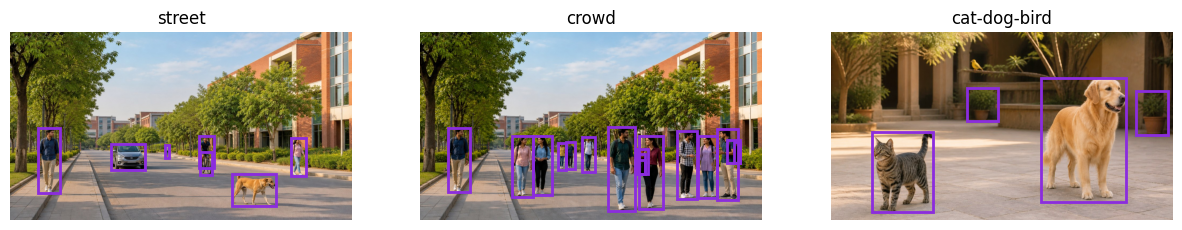

In [3]:
from ultralytics import YOLO
yolo = YOLO('yolov8n.pt')                      # downloads the weights the first time
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax_, name in zip(axes, ['street', 'crowd', 'cat-dog-bird']):
    r = yolo.predict(f'figures/{name}.jpg', imgsz=photo(name).size[::-1], conf=0.25, iou=0.7, verbose=False)[0]
    found = [yolo.names[int(c)] for c in r.boxes.cls]
    print(f'{name:13s}', {n: found.count(n) for n in sorted(set(found))})
    show(name, r.boxes.xyxy.tolist(), ax=ax_, title=name)

The cells, the parcel and the crack have no COCO class, so no detector here can find them. Their boxes are ours
(data/applications.json): the kind of list a detector for these classes would be trained on.

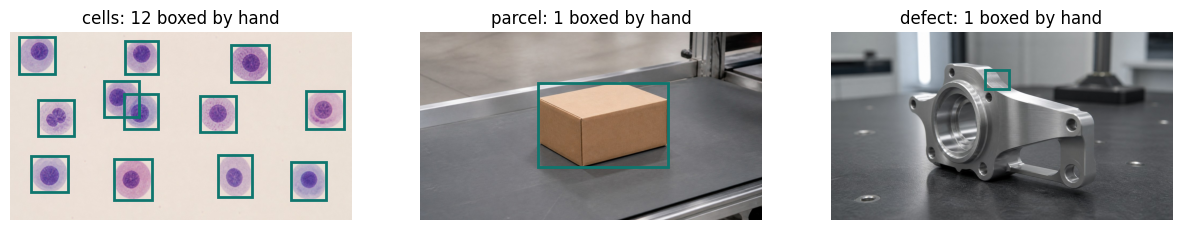

In [4]:
APPS = json.load(open('data/applications.json'))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax_, (name, lst) in zip(axes, APPS['photos'].items()):
    show(name, [b for _, b in lst], colors=['#0F766E'] * len(lst), ax=ax_, title=f'{name}: {len(lst)} boxed by hand')

The bird that YOLOv8n missed: its best bird box in the raw output, and why that box was dropped.

In [5]:
net = yolo.model.float().eval()
def raw_output(name):
    t = torch.from_numpy(np.array(photo(name))).permute(2, 0, 1)[None].float() / 255
    return net(t)[0][0].T                       # (cells, 84): c_x, c_y, w, h, then 80 class scores
out = raw_output('cat-dog-bird')
bird = 14                                       # "bird" in COCO's list of 80
is_bird = torch.where(out[:, 4:].argmax(1) == bird)[0]
k = int(is_bird[out[is_bird, 4 + bird].argmax()])
cx_, cy_, w_, h_ = out[k, :4].tolist()
best = [cx_ - w_ / 2, cy_ - h_ / 2, cx_ + w_ / 2, cy_ + h_ / 2]
gt_bird = [b for c, b in A['photos']['cat-dog-bird'] if c == 'bird'][0]
iou_bird = float(torchvision.ops.box_iou(torch.tensor([best]), torch.tensor([gt_bird], dtype=torch.float)))
second = out[k, 4:].topk(2)
print(f'best bird score {float(out[k, 4 + bird]):.3f} (cut-off 0.25) | IoU with our box {iou_bird:.3f} | '
      f'next guess: {yolo.names[int(second.indices[1])]} {float(second.values[1]):.3f}')
assert abs(float(out[k, 4 + bird]) - S['bird']['best']['score']) < 1e-3

best bird score 0.098 (cut-off 0.25) | IoU with our box 0.913 | next guess: banana 0.059


## Part 2 · From one label to a list

A classifier gives one label for the whole photo. ImageNet ResNet-50 on the courtyard photo:

In [6]:
from torchvision.models import resnet50, ResNet50_Weights
w = ResNet50_Weights.IMAGENET1K_V2
clf = resnet50(weights=w).eval()
p = clf(w.transforms()(photo('cat-dog'))[None]).softmax(-1)[0]
top = torch.topk(p, 5)
for v, i in zip(top.values, top.indices):
    print(f'{w.meta["categories"][i]:22s} {v:.3f}')
print('all 118 dog breeds together:', round(float(p[151:269].sum()), 3), '| the five cat classes:', round(float(p[281:286].sum()), 3))
assert abs(float(top.values[0]) - S['classifier']['top5'][0]['p']) < 2e-3

golden retriever       0.192
flat-coated retriever  0.015
tiger cat              0.013
Labrador retriever     0.012
tabby                  0.010
all 118 dog breeds together: 0.393 | the five cat classes: 0.03


A detector instead returns a list. YOLOv8n, with Ultralytics' own post-processing:

cat           0.921  box [115.5, 294.9, 321.3, 606.0]
potted plant  0.890  box [803.2, 139.2, 931.7, 325.1]
dog           0.889  box [406.9, 77.8, 768.7, 585.7]
potted plant  0.290  box [370.7, 253.3, 432.9, 316.6]


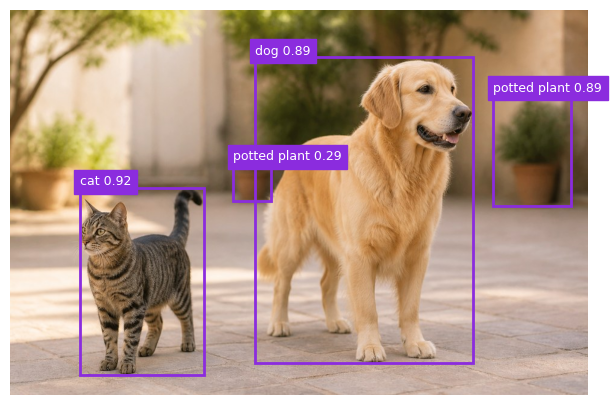

In [7]:
r = yolo.predict('figures/cat-dog.jpg', imgsz=(640, 960), conf=0.25, iou=0.7, verbose=False)[0]
for b, s, c in zip(r.boxes.xyxy, r.boxes.conf, r.boxes.cls):
    print(f'{yolo.names[int(c)]:13s} {float(s):.3f}  box {[round(v, 1) for v in b.tolist()]}')
show('cat-dog', r.boxes.xyxy.tolist(), [f'{yolo.names[int(c)]} {float(s):.2f}' for s, c in zip(r.boxes.conf, r.boxes.cls)]);

## Part 3 · Describe a box, compare two boxes

The dog's box in corner format, then as centre and size, then normalised:

In [8]:
dog = A['photos']['cat-dog'][0][1]; W, H = 960, 640
x1, y1, x2, y2 = dog
w, h = x2 - x1, y2 - y1
cx, cy = x1 + w / 2, y1 + h / 2
print('corners', dog, '| centre and size', (cx, cy, w, h))
print('normalised', [round(v, 3) for v in (cx / W, cy / H, w / W, h / H)])

corners [407, 83, 768, 588] | centre and size (587.5, 335.5, 361, 505)
normalised [0.612, 0.524, 0.376, 0.789]


The courtyard's label file in the YOLO format: one line per object, a COCO class index, then the normalised centre and size.

In [9]:
for name, b in A['photos']['cat-dog']:
    idx = [i for i, n in yolo.names.items() if n == name][0]
    print(idx, *[f'{v:.3f}' for v in ((b[0] + b[2]) / 2 / W, (b[1] + b[3]) / 2 / H, (b[2] - b[0]) / W, (b[3] - b[1]) / H)])

16 0.612 0.524 0.376 0.789
15 0.226 0.705 0.218 0.486


IoU by hand, for our box and a guess moved 60 px right and 40 px down:

In [10]:
guess = [x1 + 60, y1 + 40, x2 + 60, y2 + 40]
left, top = max(dog[0], guess[0]), max(dog[1], guess[1])
right, bottom = min(dog[2], guess[2]), min(dog[3], guess[3])
inter = max(0, right - left) * max(0, bottom - top)
area = lambda b: (b[2] - b[0]) * (b[3] - b[1])
union = area(dog) + area(guess) - inter
print(f'overlap ({left}, {top}, {right}, {bottom}) = {inter:,} px²;  union {union:,} px²;  IoU {inter / union:.3f}')
assert abs(inter / union - S['iou_practice']['iou']) < 1e-3

overlap (467, 123, 768, 588) = 139,965 px²;  union 224,645 px²;  IoU 0.623


In [11]:
def box_iou(a, b):              # a: (N, 4), b: (M, 4), corners
    lt = torch.max(a[:, None, :2], b[None, :, :2])  # overlap's top-left
    rb = torch.min(a[:, None, 2:], b[None, :, 2:])  # overlap's bottom-right
    inter = (rb - lt).clamp(min=0).prod(-1)         # (N, M); 0 if apart
    area = lambda x: (x[:, 2:] - x[:, :2]).prod(-1)
    return inter / (area(a)[:, None] + area(b)[None, :] - inter)

iou1 = lambda u, v: float(box_iou(torch.tensor([u], dtype=torch.float), torch.tensor([v], dtype=torch.float)))  # two single boxes
a, b = torch.tensor([dog], dtype=torch.float), torch.tensor([guess], dtype=torch.float)
print(box_iou(a, b), torchvision.ops.box_iou(a, b))

tensor([[0.6230]]) tensor([[0.6230]])


## Part 4 · One box is easy; several are not

The target a two-class localiser (cat, dog) learns for the single-cat photo, and for a patch of empty floor, where
"?" means the entry has no right answer and the loss skips it:

In [12]:
cb = A['photos']['cat'][0][1]; Wc, Hc = photo('cat').size
y_cat = [1, (cb[0] + cb[2]) / 2 / Wc, (cb[1] + cb[3]) / 2 / Hc, (cb[2] - cb[0]) / Wc, (cb[3] - cb[1]) / Hc, 1, 0]
print('cat photo  :', [round(v, 3) for v in y_cat])
print('empty floor:', [0, '?', '?', '?', '?', '?', '?'])
assert [round(v, 3) for v in y_cat[1:5]] == S['single']['norm']

cat photo  : [1, 0.667, 0.527, 0.319, 0.642, 1, 0]
empty floor: [0, '?', '?', '?', '?', '?', '?']


The loss compares the network's seven numbers, ŷ, with the target, y, only where it counts: all seven when there is an object, only object? when there is none. In code, on the slide's two made-up predictions:

In [13]:
def loss(p, y):
    if y[0] == 1:                                    # an object: all seven numbers count
        return sum((a - b) ** 2 for a, b in zip(p, y))
    return (p[0] - y[0]) ** 2                        # no object: only object? counts

LD = S['loss_demo']                                  # two made-up predictions, as on the slide
p_cat, p_floor, y_floor = LD['cat']['pred'], LD['floor']['pred'], [0, '?', '?', '?', '?', '?', '?']
print('cat photo   network ŷ:', p_cat)
print('            target y :', [round(v, 2) for v in y_cat])
print('            (ŷ - y)² :', [round((a - b) ** 2, 2) for a, b in zip(p_cat, y_cat)], '-> loss', round(loss(p_cat, y_cat), 2))
print('empty floor network ŷ:', p_floor)
print('            target y :', y_floor, '-> loss', round(loss(p_floor, y_floor), 2), '(only object? counts)')
assert round(loss(p_cat, y_cat), 2) == LD['cat']['loss'] and round(loss(p_floor, y_floor), 2) == LD['floor']['loss']

cat photo   network ŷ: [0.9, 0.6, 0.5, 0.4, 0.5, 0.7, 0.2]
            target y : [1, 0.67, 0.53, 0.32, 0.64, 1, 0]
            (ŷ - y)² : [0.01, 0.0, 0.0, 0.01, 0.02, 0.09, 0.04] -> loss 0.17
empty floor network ŷ: [0.3, 0.8, 0.2, 0.6, 0.1, 0.4, 0.7]
            target y : [0, '?', '?', '?', '?', '?', '?'] -> loss 0.09 (only object? counts)


Two animals, one box. If half the annotations list the dog first and half the cat, the squared error is smallest for
the average of the two boxes, and that box finds neither animal:

In [14]:
cat = A['photos']['cat-dog'][1][1]
avg = [(u + v) / 2 for u, v in zip(cat, dog)]
sq = lambda u, v: sum((a - b) ** 2 for a, b in zip(u, v))
for name, bb in [('the dog box', dog), ('the cat box', cat), ('their average', avg)]:
    print(f'{name:14s} squared error, averaged over the two orders: {(sq(bb, dog) + sq(bb, cat)) / 2:9,.0f}')
print('the average box', avg, '| IoU with the dog', round(iou1(avg, dog), 3), '| with the cat', round(iou1(avg, cat), 3))
assert abs(iou1(avg, dog) - S['average_box']['iou_dog']) < 1e-3 and abs(iou1(avg, cat) - S['average_box']['iou_cat']) < 1e-3

the dog box    squared error, averaged over the two orders:   166,282
the cat box    squared error, averaged over the two orders:   166,282
their average  squared error, averaged over the two orders:    83,141
the average box [259.5, 189.5, 544.5, 597.5] | IoU with the dog 0.225 | with the cat 0.114


## Part 5 · A candidate at every place

### 5.1 Sliding windows, and what is wrong with them

VGG16, an ImageNet classifier for 224 × 224 crops, slid over the courtyard photo 32 pixels at a time: one full run of
the network per crop. This cell takes about 30 s on a laptop and a few minutes on Colab's CPU, which is the point.

In [15]:
from torchvision.models import vgg16, VGG16_Weights
vgg = vgg16(weights=VGG16_Weights.IMAGENET1K_V1).eval()
mean, std = torch.tensor([0.485, 0.456, 0.406])[:, None, None], torch.tensor([0.229, 0.224, 0.225])[:, None, None]
xv = (torch.from_numpy(np.array(photo('cat-dog'))).permute(2, 0, 1).float() / 255 - mean) / std
size, step = 224, 32
rows, cols = (640 - size) // step + 1, (960 - size) // step + 1
print(f'{cols} across × {rows} down = {rows * cols} crops; two neighbours share {(size - step) / size:.0%} of their pixels')
crops = torch.stack([xv[:, r * step:r * step + size, c * step:c * step + size] for r in range(rows) for c in range(cols)])
t0 = time.perf_counter()
p_crops = torch.cat([vgg(crops[i:i + 16]).softmax(1) for i in range(0, len(crops), 16)])
print(f'{len(crops)} runs of VGG16: {time.perf_counter() - t0:.0f} s')
assert len(crops) == S['convwin']['n']

24 across × 14 down = 336 crops; two neighbours share 86% of their pixels


336 runs of VGG16: 32 s


Its "dog" is its 118 dog breeds added up. The window it is surest about, and how well any window can fit the dog:

surest dog window [640, 64, 864, 288]: p(dog) 0.999, IoU with our dog box 0.13
224-px windows: 336 crops; the best placed one fits the dog with IoU 0.275
448-px windows: 119 crops; the best placed one fits the dog with IoU 0.731


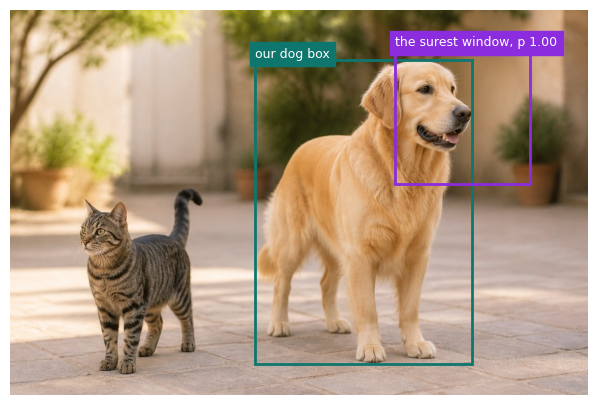

In [16]:
p_dog = p_crops[:, 151:269].sum(1)
k = int(p_dog.argmax()); r_, c_ = divmod(k, cols)
surest = [c_ * step, r_ * step, c_ * step + size, r_ * step + size]
print(f'surest dog window {surest}: p(dog) {float(p_dog[k]):.3f}, IoU with our dog box {iou1(surest, dog):.2f}')
for s_ in (224, 448):
    wins = [[x0, y0, x0 + s_, y0 + s_] for x0 in range(0, 960 - s_ + 1, 32) for y0 in range(0, 640 - s_ + 1, 32)]
    print(f'{s_}-px windows: {len(wins)} crops; the best placed one fits the dog with IoU {max(iou1(w_, dog) for w_ in wins):.3f}')
show('cat-dog', [dog, surest], ['our dog box', f'the surest window, p {float(p_dog[k]):.2f}'], colors=['#0F766E', '#8B2CDE']);
assert iou1(surest, dog) < S['windows']['best_dog']['iou'] == round(224 * 224 / area(dog), 3)
assert abs(iou1(surest, dog) - S['convwin']['best_dog']['iou']) < 0.05     # several windows score 0.99x; any of them is a poor box

The surest window holds the dog's face and some wall: the box is only the window. Even the best-placed 224-pixel
window reaches IoU 0.275, and a better fit needs more sizes and shapes, each another full set of crops.

### 5.2 YOLO, part 1: the ground-truth table

Cells of 320 × 320 pixels cut the photo into 3 × 2 cells. Each box's centre picks a cell, and that cell's record holds
the box in the cell's units. The function of the slide, run on our two boxes. The tensor has no "?": those entries
stay 0, and the loss never reads them.

In [17]:
def build_target(boxes, classes, s=320):
    y = torch.zeros(2, 3, 7)  # object? 0 everywhere
    for (x1, y1, x2, y2), k in zip(boxes, classes):
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        r, c = int(cy // s), int(cx // s)
        y[r, c, 0] = 1               # object?
        y[r, c, 1] = cx / s - c      # b_x
        y[r, c, 2] = cy / s - r      # b_y
        y[r, c, 3] = (x2 - x1) / s   # b_w
        y[r, c, 4] = (y2 - y1) / s   # b_h
        y[r, c, 5 + k] = 1           # cat or dog
    return y

boxes = [b for _, b in A['photos']['cat-dog']]                          # the dog's box, then the cat's
classes = [['cat', 'dog'].index(n) for n, _ in A['photos']['cat-dog']]   # cat 0, dog 1
Y3 = build_target(boxes, classes)
for r in range(2):
    for c in range(3):
        print(f'cell ({r}, {c}): object?, b_x, b_y, b_w, b_h, cat, dog =', [round(v, 2) for v in Y3[r, c].tolist()])
assert torch.allclose(Y3[1, 1, 1:5], torch.tensor(S['ng3']['dog']), atol=1e-3) and torch.allclose(Y3[1, 0, 1:5], torch.tensor(S['ng3']['cat']), atol=1e-3)

cell (0, 0): object?, b_x, b_y, b_w, b_h, cat, dog = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
cell (0, 1): object?, b_x, b_y, b_w, b_h, cat, dog = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
cell (0, 2): object?, b_x, b_y, b_w, b_h, cat, dog = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
cell (1, 0): object?, b_x, b_y, b_w, b_h, cat, dog = [1.0, 0.68, 0.41, 0.65, 0.97, 1.0, 0.0]
cell (1, 1): object?, b_x, b_y, b_w, b_h, cat, dog = [1.0, 0.84, 0.05, 1.13, 1.58, 0.0, 1.0]
cell (1, 2): object?, b_x, b_y, b_w, b_h, cat, dog = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0]


### 5.3 YOLO, part 2: predict, compare, train

A small CNN writes a table of the same shape, 2 × 3 × 7. Its last step puts each number in range: a sigmoid for
object?, b_x, b_y and the classes, an exponential for b_w and b_h. It is the network of the slides, with the same seed
(scripts/run_models.py).

In [18]:
torch.manual_seed(0)
toy = torch.nn.Sequential(
    torch.nn.Conv2d(3, 16, 3, 2, 1), torch.nn.ReLU(),   # 160 × 240 × 3 -> 80 × 120 × 16
    torch.nn.Conv2d(16, 32, 3, 2, 1), torch.nn.ReLU(),  # -> 40 × 60 × 32
    torch.nn.Conv2d(32, 64, 3, 2, 1), torch.nn.ReLU(),  # -> 20 × 30 × 64
    torch.nn.AdaptiveAvgPool2d((2, 3)),                 # average each cell -> 2 × 3 × 64
    torch.nn.Conv2d(64, 7, 1))                          # -> 2 × 3 × 7
xt = torch.from_numpy(np.array(photo('cat-dog').resize((240, 160)))).permute(2, 0, 1)[None].float() / 255

def predict(net, x):
    t = net(x)[0].permute(1, 2, 0)                      # (2, 3, 7): raw numbers, any sign
    return torch.cat([t[..., :3].sigmoid(), t[..., 3:5].exp(), t[..., 5:].sigmoid()], -1)

print(sum(q.numel() for q in toy.parameters()), 'weights | output', tuple(predict(toy, xt).shape))
assert sum(q.numel() for q in toy.parameters()) == S['toy']['params']

24039 weights | output (2, 3, 7)


Train it on this one photo with the loss of the slide: object? in every cell, the other six numbers only where the ground truth has an object. The dog's cell, (1, 1), moves toward its record:

step   0: loss 3.3827 | cell (1, 1): [0.49, 0.48, 0.48, 1.19, 1.07, 0.52, 0.51]


step  50: loss 0.9013 | cell (1, 1): [0.63, 0.87, 0.03, 1.07, 1.63, 0.03, 0.97]


step 300: loss 0.0023 | cell (1, 1): [0.98, 0.84, 0.01, 1.13, 1.58, 0.01, 0.99]
ground truth, cell (1, 1):            [1.0, 0.84, 0.05, 1.13, 1.58, 0.0, 1.0]


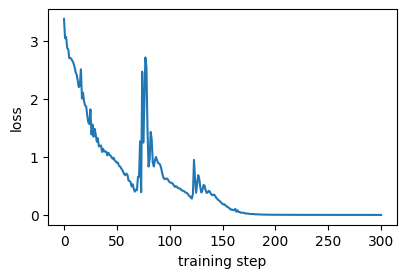

In [19]:
def yolo_loss(p, y):
    m = y[..., 0] == 1                                  # the cells that hold a centre
    loss = ((p[..., 0] - y[..., 0])**2).sum()
    loss += ((p[m, 1:] - y[m, 1:])**2).sum()
    return loss

opt = torch.optim.Adam(toy.parameters(), lr=1e-2)
hist = []
with torch.enable_grad():
    for it in range(301):
        pt = predict(toy, xt)
        L = yolo_loss(pt, Y3)
        hist.append(L.item())
        if it in (0, 50, 300):
            print(f'step {it:3d}: loss {L.item():.4f} | cell (1, 1):', [round(v, 2) for v in pt[1, 1].tolist()])
        if it < 300:
            opt.zero_grad(); L.backward(); opt.step()
print('ground truth, cell (1, 1):           ', [round(v, 2) for v in Y3[1, 1].tolist()])
plt.figure(figsize=(4.5, 2.8)); plt.plot(hist); plt.xlabel('training step'); plt.ylabel('loss');
assert abs(hist[0] - S['toy']['loss0']) < 1e-3 and hist[-1] < 0.05

It has memorised one photo, which is enough to show the mechanics. Next, one record per cell is not always enough. The crowd's people on grids of shrinking cells; every extra centre in a cell is a person with no record:

In [20]:
Wc, Hc = photo('crowd').size
centres = [((b[0] + b[2]) / 2, (b[1] + b[3]) / 2) for _, b in A['photos']['crowd']]
by_grid = []
for gc, gr in [(3, 2), (5, 3), (10, 6), (20, 11), (40, 22)]:
    per_cell = Counter((int(cy_ // (Hc / gr)), int(cx_ // (Wc / gc))) for cx_, cy_ in centres)
    shared, lost = sum(v > 1 for v in per_cell.values()), sum(v - 1 for v in per_cell.values())
    by_grid.append([gc, gr, shared, lost])
    print(f'{gc:2d} × {gr:2d} cells: {shared} hold two or more centres; {lost} of the {len(centres)} people get no record')
assert by_grid == S['crowd_cells']['by_grid']

 3 ×  2 cells: 3 hold two or more centres; 8 of the 11 people get no record
 5 ×  3 cells: 4 hold two or more centres; 5 of the 11 people get no record
10 ×  6 cells: 2 hold two or more centres; 3 of the 11 people get no record
20 × 11 cells: 1 hold two or more centres; 1 of the 11 people get no record
40 × 22 cells: 0 hold two or more centres; 0 of the 11 people get no record


The other fix keeps the big cells and gives each cell two boxes, each with a template shape. A person stands in front
of a car, and both centres fall in cell (1, 1) of the 416-pixel grid. Each object goes to the template whose shape
fits it best: the IoU of the two shapes, centred on one point.

person centre (650.5, 531.5) -> cell (1, 1) | IoU with tall 0.68, wide 0.13 -> the tall box
car    centre (629.0, 553.0) -> cell (1, 1) | IoU with tall 0.18, wide 0.94 -> the wide box


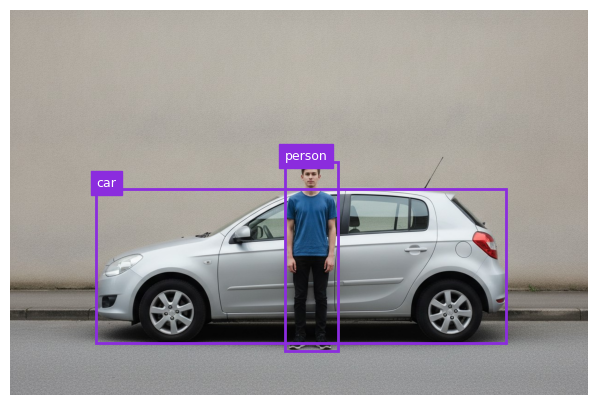

In [21]:
PCJ = json.load(open('data/person-car.json'))
s4 = 416                                                # cells of 416 px: 3 × 2 on this 1248 × 832 photo
templates = {'tall': (round(0.4 * s4), s4), 'wide': (2 * s4, round(0.8 * s4))}
def shape_iou(wh, t):                                   # both centred on one point, so only the shapes count
    inter = min(wh[0], t[0]) * min(wh[1], t[1])
    return inter / (wh[0] * wh[1] + t[0] * t[1] - inter)
for name, (x1_, y1_, x2_, y2_) in PCJ['boxes']:
    cx_, cy_, wh = (x1_ + x2_) / 2, (y1_ + y2_) / 2, (x2_ - x1_, y2_ - y1_)
    fit = {k: shape_iou(wh, t) for k, t in templates.items()}
    print(f'{name:6s} centre ({cx_:.1f}, {cy_:.1f}) -> cell ({int(cy_ // s4)}, {int(cx_ // s4)}) | '
          f'IoU with tall {fit["tall"]:.2f}, wide {fit["wide"]:.2f} -> the {max(fit, key=fit.get)} box')
    assert {k: round(v, 2) for k, v in fit.items()} == S['pc']['iou'][name]
show('person-car', [b for _, b in PCJ['boxes']], [n for n, _ in PCJ['boxes']]);

### 5.4 The real grid, and its boxes

YOLOv8n uses cells of 32 pixels: 30 × 20 of them on this photo. The dog's centre, its cell, and its box in cell
units, as on the slide:

In [22]:
s32 = 32
cx, cy = (dog[0] + dog[2]) / 2, (dog[1] + dog[3]) / 2
r, c = int(cy // s32), int(cx // s32)
print(f'{960 // s32} × {640 // s32} = {(960 // s32) * (640 // s32)} cells')
print(f'the dog: centre ({cx}, {cy}) = ({cx / s32:.2f}, {cy / s32:.2f}) cells -> cell ({r}, {c})')
target_cell = [cx / s32 - c, cy / s32 - r, (dog[2] - dog[0]) / s32, (dog[3] - dog[1]) / s32]
print('ground truth b_x, b_y, b_w, b_h =', [round(v, 3) for v in target_cell])
assert [round(v, 3) for v in target_cell] == S['ng']['dog']

30 × 20 = 600 cells
the dog: centre (587.5, 335.5) = (18.36, 10.48) cells -> cell (10, 18)
ground truth b_x, b_y, b_w, b_h = [0.359, 0.484, 11.281, 15.781]


YOLOv8n's raw output, before any post-processing, has one column per cell of three grids: 120 × 80 + 60 × 40 + 30 × 20
= 12,600 columns (Part 7 explains the two finer grids). Each column holds 84 numbers: the box as centre and size in
pixels, then 80 class scores, each already through a sigmoid. The 32-pixel grid comes last.

In [23]:
x = torch.from_numpy(np.array(photo('cat-dog'))).permute(2, 0, 1)[None].float() / 255
y, _ = net(x)
print(y.shape)                             # (1, 84, 12600)
raw = y[0].T                               # (12600, 84): one row per cell
off = 9600 + 2400                          # the 32-pixel grid comes last
rec = lambda r, c: raw[off + r * 30 + c]   # the 84 numbers of cell (r, c)
d = rec(10, 18)
top = d[4:].topk(3)
print('cell (10, 18): box (c_x, c_y, w, h) =', [round(v, 1) for v in d[:4].tolist()])
print('   its highest class scores:', [(yolo.names[int(i)], round(float(v), 4)) for v, i in zip(top.values, top.indices)])
logit = lambda q: math.log(q / (1 - q))     # undo the sigmoid
p_dog, p_cat = float(d[4 + 16]), float(d[4 + 15])
print(f'   dog σ({logit(p_dog):.2f}) = {p_dog:.2f}, cat σ({logit(p_cat):.2f}) = {p_cat:.4f}')
wall = rec(4, 8)
print('cell (4, 8), on the wall: highest class score', yolo.names[int(wall[4:].argmax())], round(float(wall[4:].max()), 4))
assert abs(p_dog - S['cell']['p_dog']) < 1e-3

torch.Size([1, 84, 12600])
cell (10, 18): box (c_x, c_y, w, h) = [588.4, 331.9, 362.3, 512.5]
   its highest class scores: [('dog', 0.8706), ('cat', 0.0001), ('skateboard', 0.0001)]
   dog σ(1.91) = 0.87, cat σ(-9.25) = 0.0001
cell (4, 8), on the wall: highest class score potted plant 0.0001


Read the box back out of the dog's cell: first in the cell's units, the form of the ground truth, then back in pixels.

In [24]:
cx_p, cy_p, w_p, h_p = d[:4].tolist()                   # YOLOv8n's box at this cell, in pixels
b = [cx_p / s32 - 18, cy_p / s32 - 10, w_p / s32, h_p / s32]
print("in the cell's units: b_x, b_y, b_w, b_h =", [round(v, 3) for v in b])
corner = (18 * s32, 10 * s32)                           # the cell's top-left corner
centre = (corner[0] + b[0] * s32, corner[1] + b[1] * s32)
size_px = (b[2] * s32, b[3] * s32)
box = [centre[0] - size_px[0] / 2, centre[1] - size_px[1] / 2, centre[0] + size_px[0] / 2, centre[1] + size_px[1] / 2]
print('corner', corner, '| centre', [round(v, 1) for v in centre], '| size', [round(v, 1) for v in size_px])
print('box', [round(v, 1) for v in box], '| IoU with our box', round(iou1(box, dog), 2))
assert np.allclose(b, S['ng']['pred'], atol=2e-3) and abs(iou1(box, dog) - S['cell']['iou']) < 1e-2

in the cell's units: b_x, b_y, b_w, b_h = [0.388, 0.371, 11.323, 16.015]
corner (576, 320) | centre [588.4, 331.9] | size [362.3, 512.5]


box [407.2, 75.6, 769.6, 588.1] | IoU with our box 0.98


Every cell writes a box, the wall and floor cells too. A box's score is its cell's best class score; keep the boxes scoring at least 0.25. Five sample cells first, then all of them:

dog   cell (10, 18): dog           0.8706 -> keep
cat   cell (14,  6): cat           0.9171 -> keep
plant cell ( 7, 27): potted plant  0.8899 -> keep
wall  cell ( 4,  8): potted plant  0.0001 -> drop
floor cell (18, 25): dining table  0.0000 -> drop
30 of the 600 boxes pass: {'potted plant': 10, 'dog': 10, 'cat': 10}
31 of all 12600 pass, with the finer grids of Part 7


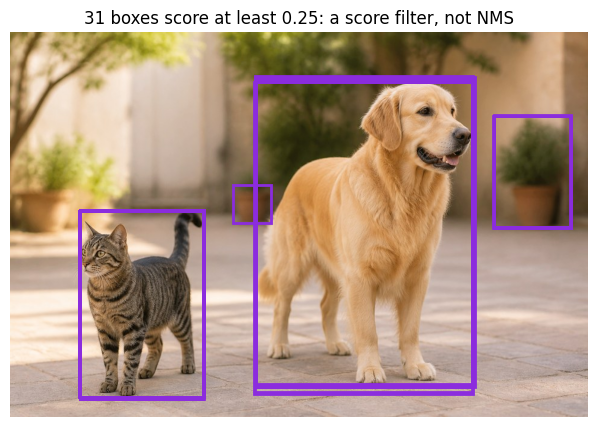

In [25]:
from torchvision.ops import box_convert
xyxy = lambda b: box_convert(b, 'cxcywh', 'xyxy')       # centre and size -> corners
boxes = xyxy(raw[:, :4])                                # every cell's box, in pixels
score, label = raw[:, 4:].max(1)                        # its score: the best of the 80 class scores
for name, (r_, c_) in S['grid']['samples']:
    k = off + r_ * 30 + c_
    print(f'{name:5s} cell ({r_:2d}, {c_:2d}): {yolo.names[int(label[k])]:13s} {float(score[k]):.4f} ->', 'keep' if score[k] >= 0.25 else 'drop')
keep = score >= 0.25
on32 = keep[off:]
print(int(on32.sum()), 'of the 600 boxes pass:', dict(Counter(yolo.names[int(c)] for c in label[off:][on32])))
print(int(keep.sum()), 'of all', len(raw), 'pass, with the finer grids of Part 7')
show('cat-dog', boxes[keep].tolist(), title=f'{int(keep.sum())} boxes score at least 0.25: a score filter, not NMS');
assert int(on32.sum()) == 30 and int(keep.sum()) == S['nms_courtyard']['n_candidates']

## Part 6 · One box per object: non-maximum suppression

NMS as written on the slide, on the 31 boxes that passed the score filter, checked against torchvision's:

In [26]:
def nms(boxes, scores, thr=0.7):
    order = scores.argsort(descending=True)
    keep = []
    while order.numel() > 0:
        i, rest = order[:1], order[1:]
        keep.append(i)
        ious = box_iou(boxes[i], boxes[rest])[0]
        order = rest[ious <= thr]
    return torch.cat(keep)

b, s, l = boxes[keep], score[keep], label[keep]
ours = nms(b, s)
theirs = torchvision.ops.nms(b, s, 0.7)
print('ours', ours.tolist(), '| torchvision', theirs.tolist(), '| torchvision, class by class', torchvision.ops.batched_nms(b, s, l, 0.7).tolist())
for i in ours: print(f'{yolo.names[int(l[i])]:13s} {float(s[i]):.3f}')
assert ours.tolist() == theirs.tolist() and len(ours) == len(S['nms_courtyard']['kept'])

ours [24, 6, 14, 0] | torchvision [24, 6, 14, 0] | torchvision, class by class [24, 6, 14, 0]
cat           0.921
potted plant  0.890
dog           0.889
potted plant  0.290


The dog's ten boxes against the one NMS keeps:

In [27]:
d = (l == 16)
db, ds = b[d], s[d]
top = int(ds.argmax())
print([round(float(v), 3) for v in box_iou(db[top, None], db)[0]])

[0.962, 0.956, 0.994, 1.0, 0.995, 0.987, 0.985, 0.98, 0.977, 0.98]


The IoU threshold on the crowd photo, class-aware against class-agnostic NMS on the street photo, and two dogs of one class:

In [28]:
def candidates(name, conf=0.25):
    out = raw_output(name)
    sc, lb = out[:, 4:].max(1)
    k = sc >= conf
    bx = torch.cat([out[:, :2] - out[:, 2:4] / 2, out[:, :2] + out[:, 2:4] / 2], 1)
    return bx[k], sc[k], lb[k]
cb_, cs, cl = candidates('crowd'); p_ = cl == 0
for thr in (0.0, 0.3, 0.5, 0.7, 0.9, 0.95):
    print(f'threshold {thr}: {len(nms(cb_[p_], cs[p_], thr))} people kept from {int(p_.sum())} candidates')
sb, ss, sl_ = candidates('street')
aware = torchvision.ops.batched_nms(sb, ss, sl_, 0.3)
agnostic = torchvision.ops.nms(sb, ss, 0.3)
print('class-aware keeps', sorted(yolo.names[int(c)] for c in sl_[aware]))
print('class-agnostic keeps', sorted(yolo.names[int(c)] for c in sl_[agnostic]))
tb, ts, tl = candidates('two-dogs'); dg = tl == 16
kept_dogs = nms(tb[dg], ts[dg])
print(int(dg.sum()), 'dog boxes ->', len(kept_dogs), 'kept; IoU between the two kept boxes:',
      round(float(box_iou(tb[dg][kept_dogs[:1]], tb[dg][kept_dogs[1:2]])), 3))
assert int(dg.sum()) == S['nms_two_dogs']['n'] and len(kept_dogs) == 2

threshold 0.0: 9 people kept from 112 candidates
threshold 0.3: 11 people kept from 112 candidates
threshold 0.5: 11 people kept from 112 candidates
threshold 0.7: 11 people kept from 112 candidates
threshold 0.9: 11 people kept from 112 candidates
threshold 0.95: 13 people kept from 112 candidates


class-aware keeps ['bicycle', 'car', 'dog', 'person', 'person', 'person', 'person']
class-agnostic keeps ['car', 'dog', 'person', 'person', 'person', 'person']


20 dog boxes -> 2 kept; IoU between the two kept boxes: 0.0


The whole detector at test time, as on the slide:

In [29]:
from torchvision.ops import batched_nms
def detect(x, net):
    y = net(x)[0][0]              # (84, 12600)
    box = xyxy(y[:4].T)           # (12600, 4)
    score, label = y[4:].max(0)   # (12600,)
    k = score >= 0.25             # 31 True
    box, score, label = box[k], score[k], label[k]
    k = batched_nms(box, score, label, 0.7)  # 4
    return box[k], score[k], label[k]

for bb, sc, lb in zip(*detect(x, net)):
    print(f'{yolo.names[int(lb)]:13s} {float(sc):.3f}  box {[round(v, 1) for v in bb.tolist()]}')

cat           0.921  box [115.5, 294.9, 321.3, 606.0]
potted plant  0.890  box [803.2, 139.2, 931.7, 325.1]
dog           0.889  box [406.9, 77.8, 768.7, 585.7]
potted plant  0.290  box [370.7, 253.3, 432.9, 316.6]


## Part 7 · Small and large objects: three grids

Which grid produced each kept detection on the street photo with the bus?

In [30]:
im = photo('scale'); Wp, Hp = im.size
out = raw_output('scale')
sizes = [(Hp // s) * (Wp // s) for s in (8, 16, 32)]
print('cells per grid', sizes, '=', sum(sizes))
sc, lb = out[:, 4:].max(1); k = torch.where(sc >= 0.25)[0]
bx = torch.cat([out[:, :2] - out[:, 2:4] / 2, out[:, :2] + out[:, 2:4] / 2], 1)
kept = k[torchvision.ops.batched_nms(bx[k], sc[k], lb[k], 0.7)]
stride = lambda i: 8 if i < sizes[0] else 16 if i < sizes[0] + sizes[1] else 32
for i in kept: print(f'{yolo.names[int(lb[i])]:8s} {float(sc[i]):.3f}  from the {stride(int(i))}-px grid')

cells per grid [14080, 3520, 880] = 18480
bus      0.930  from the 32-px grid
person   0.848  from the 16-px grid
person   0.681  from the 8-px grid
bicycle  0.587  from the 16-px grid


Boxes that turn. The crack's axis-aligned box against an oriented one, then four slanted ships moored side by side.
The IoU of two rotated boxes is the area of their overlap, a polygon, over their union; shapely computes the areas.

In [31]:
from shapely.geometry import box as rect
from shapely import affinity
def oriented(cx, cy, w, h, deg):                        # a w × h box centred at (cx, cy), turned by deg
    return affinity.rotate(rect(cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2), deg, origin=(cx, cy))
poly_iou = lambda a, b: a.intersection(b).area / a.union(b).area

crack = oriented(618, 182, 96, 14, 46)
x1_, y1_, x2_, y2_ = crack.bounds
aabb = rect(math.floor(x1_), math.floor(y1_), math.ceil(x2_), math.ceil(y2_))
print('crack: axis-aligned box', [int(v) for v in aabb.bounds], f'is {aabb.area / crack.area:.1f} times the oriented one; IoU {poly_iou(crack, aabb):.2f}')
ships = [oriented(130 + 64 * k, 160, 280, 40, -45) for k in range(4)]
iou_obb, iou_aabb = poly_iou(ships[0], ships[1]), poly_iou(rect(*ships[0].bounds), rect(*ships[1].bounds))
print(f'neighbouring ships: oriented boxes IoU {iou_obb:.2f}, axis-aligned boxes IoU {iou_aabb:.2f}')
assert round(poly_iou(crack, aabb), 2) == S['obb']['crack']['iou'] and round(iou_aabb, 2) == S['obb']['ships']['iou_aabb'] and iou_obb == 0

crack: axis-aligned box [579, 142, 657, 222] is 4.6 times the oriented one; IoU 0.22
neighbouring ships: oriented boxes IoU 0.00, axis-aligned boxes IoU 0.56


## Part 8 · Measuring a detector

The teaching example of the slides: five annotated dogs, A to E, and eight detections made up for teaching
(data/dog-park.json). The IoU of every box (rows, highest score first) with every dog (columns):

In [32]:
DP = json.load(open('data/dog-park.json'))
ids = [k for k, _, _ in DP['gt']]                                       # dogs A to E
gts = [('park', b) for _, _, b in DP['gt']]                             # (photo, box)
ranked = sorted(DP['dets'], key=lambda d: -d[0])
dets = [('park', sc, bx) for sc, bx, _ in ranked]                       # (photo, score, box)
what = [w_ for _, _, w_ in ranked]                                      # what a box sits on, when it is not a dog
ious = box_iou(torch.tensor([bx for _, _, bx in dets], dtype=torch.float), torch.tensor([g for _, g in gts], dtype=torch.float))
print('      ', '     '.join(ids))
for i, row in enumerate(ious.tolist()):
    print(f'#{i + 1} {dets[i][1]:.2f}', ' '.join(f'{v:5.2f}' for v in row))

       A     B     C     D     E
#1 0.95  0.00  0.88  0.00  0.00  0.00
#2 0.90  0.81  0.00  0.00  0.00  0.00
#3 0.80  0.00  0.00  0.00  0.00  0.00
#4 0.70  0.00  0.00  0.76  0.00  0.00
#5 0.60  0.00  0.00  0.00  0.00  0.00
#6 0.45  0.00  0.00  0.04  0.40  0.00
#7 0.35  0.00  0.00  0.00  0.68  0.00
#8 0.20  0.00  0.00  0.00  0.00  0.00


Judge every box in score order. It is a true positive (TP) if its IoU with a dog not yet found is at least 0.5, and
that dog is then found; every other box is a false positive (FP). Dogs that no box found are false negatives (FN).
With the AP code further down, the whole evaluator is about twenty lines:

#1  0.95  IoU 0.88 with dog B              TP
#2  0.90  IoU 0.81 with dog A              TP
#3  0.80  IoU 0 with every dog (the bag)   FP
#4  0.70  IoU 0.76 with dog C              TP
#5  0.60  IoU 0 with every dog (the bench) FP
#6  0.45  IoU 0.40 with dog D              FP
#7  0.35  IoU 0.68 with dog D              TP
#8  0.20  IoU 0 with every dog (a bush)    FP
TP 4, FP 4, FN 1: dog E has no box


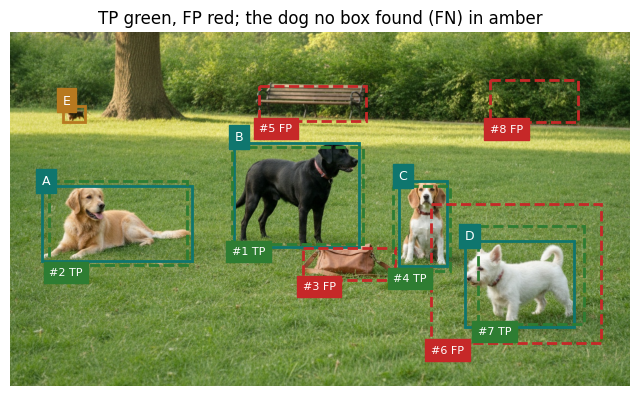

In [33]:
def match(dets, gts, thr=0.5):
    # dets: (photo, score, box); gts: (photo, box). Returns TP or FP for each box, highest score first, and the objects found.
    found, hits = set(), []
    for ph, sc, bx in sorted(dets, key=lambda d: -d[1]):
        v, j = max(((iou1(bx, g), j) for j, (gp, g) in enumerate(gts) if gp == ph and j not in found), default=(0.0, None))
        hits.append(v >= thr)
        if hits[-1]:
            found.add(j)
    return hits, found

hits, found = match(dets, gts)
for i, h in enumerate(hits):
    v, j = ious[i].max(0)
    why = f'IoU {float(v):.2f} with dog {ids[int(j)]}' if v > 0 else f'IoU 0 with every dog ({what[i]})'
    print(f'#{i + 1}  {dets[i][1]:.2f}  {why:32s}', 'TP' if h else 'FP')
fn = [ids[j] for j in range(len(gts)) if j not in found]
print(f'TP {sum(hits)}, FP {len(hits) - sum(hits)}, FN {len(fn)}: dog', ', '.join(fn), 'has no box')
ax = show('dog-park', [g for _, g in gts], ids, colors=['#0F766E' if j in found else '#B7791F' for j in range(len(gts))])
for i, (h, (_, sc, bx)) in enumerate(zip(hits, dets)):
    col = '#2E7D32' if h else '#C62828'
    ax.add_patch(patches.Rectangle((bx[0], bx[1]), bx[2] - bx[0], bx[3] - bx[1], fill=False, lw=2, ec=col, ls='--'))
    ax.text(bx[0], bx[3] + 22, f'#{i + 1} ' + ('TP' if h else 'FP'), color='white', fontsize=8, backgroundcolor=col)
ax.set_title('TP green, FP red; the dog no box found (FN) in amber');
assert hits == S['teach']['hit'] and fn == S['teach']['fn']

Precision = TP / (TP + FP), of the boxes we kept; recall = TP / (TP + FN), of the five dogs. Three score thresholds, as on the slide:

In [34]:
for cut, want in zip((0.85, 0.5, 0.1), S['teach']['cuts']):
    kept = [d for d in dets if d[1] >= cut]
    h, _ = match(kept, gts)
    tp, fp, fn_ = sum(h), len(h) - sum(h), len(gts) - sum(h)
    print(f'keep scores ≥ {cut}: {len(kept)} boxes, TP {tp}, FP {fp}, FN {fn_} | '
          f'precision {tp}/{len(kept)} = {tp / len(kept):.2f}, recall {tp}/{len(gts)} = {tp / len(gts):.2f}')
    assert (tp, fp, fn_) == (want['tp'], want['fp'], want['fn'])

keep scores ≥ 0.85: 2 boxes, TP 2, FP 0, FN 3 | precision 2/2 = 1.00, recall 2/5 = 0.40
keep scores ≥ 0.5: 5 boxes, TP 3, FP 2, FN 2 | precision 3/5 = 0.60, recall 3/5 = 0.60
keep scores ≥ 0.1: 8 boxes, TP 4, FP 4, FN 1 | precision 4/8 = 0.50, recall 4/5 = 0.80


Every threshold at once: the precision-recall curve. AP is the area under its envelope, the best precision still reachable at each recall. The code of the slide:

precision [1.0, 1.0, 0.67, 0.75, 0.6, 0.5, 0.57, 0.5]
recall    [0.2, 0.4, 0.4, 0.6, 0.6, 0.6, 0.8, 0.8]
envelope  [1.0, 1.0, 0.75, 0.75, 0.6, 0.57, 0.57, 0.5]
AP = 0.664


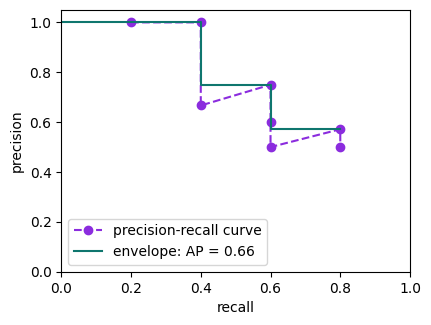

In [35]:
h = torch.tensor(hits)
tp = h.cumsum(0)  # true positives so far
fp = (~h).cumsum(0)  # false positives so far
p = tp / (tp + fp)  # precision
r = tp / 5  # recall: 5 dogs
curve = p.clone()
for i in range(len(p) - 2, -1, -1):
    p[i] = max(p[i], p[i + 1])  # envelope
w = r.diff(prepend=torch.zeros(1))  # widths
ap = (w * p).sum()
print('precision', [round(v, 2) for v in curve.tolist()])
print('recall   ', [round(v, 2) for v in r.tolist()])
print('envelope ', [round(v, 2) for v in p.tolist()])
print('AP =', round(float(ap), 3))
plt.figure(figsize=(4.5, 3.4))
plt.plot(r.numpy(), curve.numpy(), 'o--', color='#8B2CDE', label='precision-recall curve')
up = w > 0                                               # the rows that add recall: the strips of the area
plt.step(np.r_[0, r[up].numpy()], np.r_[p[up][0].item(), p[up].numpy()], where='pre', color='#0F766E', label=f'envelope: AP = {float(ap):.2f}')
plt.xlabel('recall'); plt.ylabel('precision'); plt.xlim(0, 1); plt.ylim(0, 1.05); plt.legend(loc='lower left');
assert abs(float(ap) - S['teach']['ap']) < 1e-3

Stricter IoU: AP at each of COCO's ten IoU thresholds, 0.50 to 0.95, and their mean, COCO's headline AP. Box #7 overlaps dog D with IoU 0.68, so it stops counting from 0.70:

In [36]:
def ap_all_points(hits, n):                              # the code above, as a function
    h = torch.tensor(hits)
    tp, fp = h.cumsum(0), (~h).cumsum(0)
    p, r = tp / (tp + fp), tp / n
    p = p.flip(0).cummax(0).values.flip(0)               # the envelope
    return float((r.diff(prepend=torch.zeros(1)) * p).sum())

thrs = [round(float(t), 2) for t in np.arange(0.5, 0.96, 0.05)]
aps = [ap_all_points(match(dets, gts, t)[0], len(gts)) for t in thrs]
for t, a in zip(thrs, aps): print(f'IoU ≥ {t:.2f}: AP {a:.2f}')
print(f'mean over the ten thresholds: {np.mean(aps):.2f}')
assert [round(a, 2) for a in aps] == S['teach']['ap_by'] and round(float(np.mean(aps)), 3) == S['teach']['ap_mean']

IoU ≥ 0.50: AP 0.66
IoU ≥ 0.55: AP 0.66
IoU ≥ 0.60: AP 0.66
IoU ≥ 0.65: AP 0.66
IoU ≥ 0.70: AP 0.55
IoU ≥ 0.75: AP 0.55
IoU ≥ 0.80: AP 0.40
IoU ≥ 0.85: AP 0.20
IoU ≥ 0.90: AP 0.00
IoU ≥ 0.95: AP 0.00
mean over the ten thresholds: 0.44


mAP: one AP per class, then their mean. YOLOv8n on our eight photos and seven classes, every detection down to a
score of 0.01. COCO reads the envelope at 101 recall values, 0, 0.01, ..., 1, instead of taking its exact area; the
slide does the same.

In [37]:
def ap_101(hits, n):
    if not hits:
        return 0.0
    tp = np.cumsum(hits); fp = np.cumsum([not h_ for h_ in hits])
    p, r = tp / (tp + fp), tp / n
    p = np.maximum.accumulate(p[::-1])[::-1]                            # the envelope
    k = np.searchsorted(r, np.linspace(0, 1, 101), side='left')         # the first row that reaches each recall
    return float(np.mean([p[i] if i < len(p) else 0.0 for i in k]))

def yolo_dets(name, conf=0.01):
    rr = yolo.predict(f'figures/{name}.jpg', imgsz=photo(name).size[::-1], conf=conf, iou=0.7, verbose=False)[0]
    return [(name, yolo.names[int(c)], float(s), b.tolist()) for b, s, c in zip(rr.boxes.xyxy, rr.boxes.conf, rr.boxes.cls)]

def benchmark(dets):
    # dets: (photo, class, score, box) on all eight photos -> {class: (AP at IoU 0.5, mean AP over the ten thresholds)}
    res = {}
    for cls in A['classes']:
        g = [(n, bb) for n, lst in A['photos'].items() for c, bb in lst if c == cls]
        ds = [(ph, sc, bx) for ph, c, sc, bx in dets if c == cls]
        per = [ap_101(match(ds, g, t)[0], len(g)) for t in thrs]
        res[cls] = (per[0], float(np.mean(per)))
    return res
means = lambda res: (float(np.mean([v[0] for v in res.values()])), float(np.mean([v[1] for v in res.values()])))

ydets = [d for n in A['photos'] for d in yolo_dets(n)]
yres = benchmark(ydets)
for cls, (a50, a) in sorted(yres.items(), key=lambda kv: -kv[1][1]):
    print(f'{cls:8s} AP50 {a50:.3f}   AP {a:.3f}')
map50, map_ = means(yres)
print(f'YOLOv8n: mAP@0.5 = {map50:.3f}, mAP = AP@[.5:.95] = {map_:.3f}')
assert abs(map50 - S['benchmark']['yolo']['map50']) < 0.01 and abs(map_ - S['benchmark']['yolo']['map']) < 0.01

car      AP50 1.000   AP 1.000
bus      AP50 1.000   AP 1.000
dog      AP50 1.000   AP 0.966
cat      AP50 1.000   AP 0.966
person   AP50 1.000   AP 0.919
bird     AP50 1.000   AP 0.900
bicycle  AP50 1.000   AP 0.801
YOLOv8n: mAP@0.5 = 1.000, mAP = AP@[.5:.95] = 0.936


Eight clean photos are not a benchmark: on COCO's 5,000 validation photos the published AP of YOLOv8n is 0.373.
Libraries do the matching, ranking and averaging for you; the slide's version uses torchmetrics
(`pip install torchmetrics pycocotools`):

```python
from torchmetrics.detection import MeanAveragePrecision
metric = MeanAveragePrecision(iou_type="bbox")
metric.update(preds=[{"boxes": boxes, "scores": scores, "labels": labels}],
              target=[{"boxes": gt_boxes, "labels": gt_labels}])
res = metric.compute()          # res["map"] = AP@[.5:.95], res["map_50"] = AP@0.5
```

## Appendix A · DETR: a fixed set of slots, matched to objects

A.1, Problem 2: which dog belongs in slot 1? Two perfect slots, one on each dog, scored against an annotation that
happens to list the right dog first. Boxes are normalised (c_x, c_y, w, h).

In [38]:
W2, H2 = photo('two-dogs').size
left_dog, right_dog = [bb for _, bb in sorted(A['photos']['two-dogs'], key=lambda x_: x_[1][0])]
nrm = lambda bb: torch.tensor([(bb[0] + bb[2]) / 2 / W2, (bb[1] + bb[3]) / 2 / H2, (bb[2] - bb[0]) / W2, (bb[3] - bb[1]) / H2])
slots = [nrm(left_dog), nrm(right_dog)]                  # a perfect answer: slot 1 on the left dog, slot 2 on the right
listed = [nrm(right_dog), nrm(left_dog)]                 # the annotation lists the right dog first
by_position = sum(float((s_ - t_).abs().sum()) for s_, t_ in zip(slots, listed))
print(f'L1, slot k against entry k: {by_position:.3f} | each slot against its own dog: 0')
assert abs(by_position - S['slots']['perfect']) < 2e-3

L1, slot k against entry k: 1.207 | each slot against its own dog: 0


DETR on the courtyard photo: 100 queries, each a class (91 COCO ids or "no object") and a normalised box.

In [39]:
from transformers import DetrImageProcessor, DetrForObjectDetection
proc = DetrImageProcessor.from_pretrained('facebook/detr-resnet-50')
detr = DetrForObjectDetection.from_pretrained('facebook/detr-resnet-50', attn_implementation='eager').eval()
out = detr(**proc(images=photo('cat-dog'), return_tensors='pt'), output_attentions=True)
prob = out.logits.softmax(-1)[0]                 # (100, 92); the last column is "no object"
print('queries saying "no object" with p > 0.9:', int((prob[:, -1] > 0.9).sum()))
for q in torch.argsort(prob[:, -1])[:6].tolist():
    c = int(prob[q, :-1].argmax())
    print(f'query {q:2d}: {detr.config.id2label[c]:12s} p = {float(prob[q, c]):.3f}  box (cx, cy, w, h) = {[round(v, 3) for v in out.pred_boxes[0, q].tolist()]}')

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


queries saying "no object" with p > 0.9: 88
query 71: dog          p = 0.999  box (cx, cy, w, h) = [0.615, 0.526, 0.377, 0.787]
query 61: cat          p = 0.999  box (cx, cy, w, h) = [0.224, 0.706, 0.216, 0.483]
query 12: potted plant p = 0.998  box (cx, cy, w, h) = [0.904, 0.364, 0.139, 0.287]
query 81: potted plant p = 0.989  box (cx, cy, w, h) = [0.424, 0.419, 0.08, 0.15]
query 48: potted plant p = 0.973  box (cx, cy, w, h) = [0.082, 0.389, 0.163, 0.269]
query 15: potted plant p = 0.843  box (cx, cy, w, h) = [0.162, 0.262, 0.326, 0.522]


Where query 71 (the dog) looked: its cross-attention in the last decoder layer, averaged over the 8 heads.

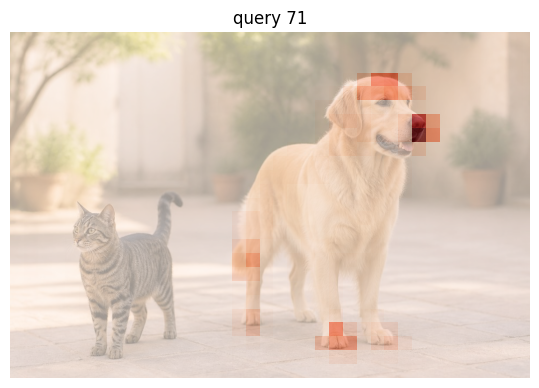

In [40]:
att = out.cross_attentions[-1][0].mean(0)        # (100, 950): 25 x 38 image tokens
plt.figure(figsize=(7, 4.5)); plt.imshow(photo('cat-dog'))
plt.imshow(att[71].reshape(25, 38), extent=(0, 38 * 32 / 1.25, 25 * 32 / 1.25, 0), alpha=.6, cmap='Reds'); plt.xlim(0, 960); plt.ylim(640, 0); plt.axis('off'); plt.title('query 71');

Matching, as DETR's training does it: the cost of every (target, query) pair, then the cheapest one-to-one pairing.

In [41]:
def cxcywh_to_xyxy(b): return torch.cat([b[..., :2] - b[..., 2:] / 2, b[..., :2] + b[..., 2:] / 2], -1)
out2 = detr(**proc(images=photo('two-dogs'), return_tensors='pt'))
p2, b2 = out2.logits.softmax(-1)[0], out2.pred_boxes[0]
Q = S['match']['queries']                         # four of the 100 queries, as on the slide
gt = torch.tensor(S['match']['target_boxes'])     # left dog, right dog, normalised (cx, cy, w, h)
dog_id = 18                                       # "dog" in DETR's labels
cost = (-p2[Q][:, dog_id][None, :]
        + 5 * torch.cdist(gt, b2[Q], p=1)
        - 2 * torchvision.ops.generalized_box_iou(cxcywh_to_xyxy(gt), cxcywh_to_xyxy(b2[Q])))
print(np.round(cost.numpy(), 2))
from scipy.optimize import linear_sum_assignment
rows, cols = linear_sum_assignment(cost.numpy())
print('left dog -> query', Q[cols[0]], '| right dog -> query', Q[cols[1]])
brute = min(itertools.permutations(range(len(Q)), 2), key=lambda pr: float(cost[0, pr[0]] + cost[1, pr[1]]))
assert list(cols) == list(brute)

[[      -2.95        3.09        6.07       -1.71]
 [       3.08        -2.9        4.47        4.26]]
left dog -> query 61 | right dog -> query 98


Greedy can lose; the Hungarian algorithm finds the best total:

In [42]:
T = np.array([[1, 2], [2, 9]])
print('greedy: left dog takes q1 (1), right dog gets q2 (9): total 10')
print('best:', linear_sum_assignment(T), 'total', T[0, 1] + T[1, 0])

greedy: left dog takes q1 (1), right dog gets q2 (9): total 10
best: (array([0, 1]), array([1, 0])) total 4


DETR on the same eight photos, with the evaluator of Part 8:

In [43]:
def detr_dets(name):
    im = photo(name)
    o = detr(**proc(images=im, return_tensors='pt'))
    res = proc.post_process_object_detection(o, threshold=0.01, target_sizes=[im.size[::-1]])[0]
    return [(name, detr.config.id2label[int(c)], float(s), bb.tolist()) for bb, s, c in zip(res['boxes'], res['scores'], res['labels'])]
print('DETR: mAP@0.5 = %.3f, mAP = AP@[.5:.95] = %.3f' % means(benchmark([d for n in A['photos'] for d in detr_dets(n)])))

DETR: mAP@0.5 = 1.000, mAP = AP@[.5:.95] = 0.882


On COCO's 5,000 validation photos the published numbers are 37.3 (YOLOv8n) and 42.0 (DETR-R50).

## Appendix B · More depth

The appendix slides that use real model numbers: VGG16's windows in one pass, YOLOv8n's own box form and its loss,
and real detections measured.

One pass for every window. VGG16's three dense layers, written as a 7 × 7 convolution and two 1 × 1 convolutions,
accept the whole photo, so one pass gives all 14 × 24 window answers. Compare it with Part 5's 336 crops:

In [44]:
fc1, fc2, fc3 = vgg.classifier[0], vgg.classifier[3], vgg.classifier[6]
conv1 = torch.nn.Conv2d(512, 4096, 7)
conv1.weight.data, conv1.bias.data = fc1.weight.data.view(4096, 512, 7, 7), fc1.bias.data
conv2, conv3 = torch.nn.Conv2d(4096, 4096, 1), torch.nn.Conv2d(4096, 1000, 1)
conv2.weight.data, conv2.bias.data = fc2.weight.data.view(4096, 4096, 1, 1), fc2.bias.data
conv3.weight.data, conv3.bias.data = fc3.weight.data.view(1000, 4096, 1, 1), fc3.bias.data
head = torch.nn.Sequential(conv1, torch.nn.ReLU(), conv2, torch.nn.ReLU(), conv3).eval()
t0 = time.perf_counter()
one = head(vgg.features(xv[None])).softmax(1)[0]          # (1000, 14, 24): one answer per window
print(f'one pass: {time.perf_counter() - t0:.1f} s for {one.shape[1]} × {one.shape[2]} answers')
d1, c1 = one[151:269].sum(0).flatten(), one[281:286].sum(0).flatten()
d2, c2 = p_crops[:, 151:269].sum(1), p_crops[:, 281:286].sum(1)
verdict = lambda dg_, ct_: torch.where(dg_ >= .5, 1, torch.where(ct_ >= .5, 2, 0))   # dog, cat or neither
agree = int((verdict(d1, c1) == verdict(d2, c2)).sum())
k1 = int(d1.argmax()); r1_, c1_ = divmod(k1, one.shape[2])
win1 = [c1_ * 32, r1_ * 32, c1_ * 32 + 224, r1_ * 32 + 224]
print(f'the one pass and the crops agree on {agree} of {len(d1)} windows')
print(f'surest dog window of the one pass {win1}: p {float(d1[k1]):.3f}, IoU with our dog box {iou1(win1, dog):.2f}')
assert abs(agree - S['convwin']['agree']) <= 3

one pass: 0.8 s for 14 × 24 answers
the one pass and the crops agree on 317 of 336 windows
surest dog window of the one pass [640, 64, 864, 288]: p 0.997, IoU with our dog box 0.13


YOLOv8n's own box form: the distances from a cell's centre to the box's four edges. At cell (10, 18), the target from our box and what the network wrote:

In [45]:
d = rec(10, 18)
cx_p, cy_p, w_p, h_p = d[:4].tolist()
ax_, ay_ = (18 + .5) * 32, (10 + .5) * 32                # the centre of cell (10, 18)
pred_box = [cx_p - w_p / 2, cy_p - h_p / 2, cx_p + w_p / 2, cy_p + h_p / 2]
target = [ax_ - dog[0], ay_ - dog[1], dog[2] - ax_, dog[3] - ay_]
ltrb = [ax_ - pred_box[0], ay_ - pred_box[1], pred_box[2] - ax_, pred_box[3] - ay_]
l1px = sum(abs(u - v) for u, v in zip(ltrb, target))
print('cell centre', (ax_, ay_), '| target l, t, r, b =', target, '| YOLOv8n:', [round(v, 1) for v in ltrb], f'| L1 {l1px:.1f} px')
assert abs(l1px - S['cell']['l1']) < 0.1

cell centre (592.0, 336.0) | target l, t, r, b = [185.0, 253.0, 176.0, 252.0] | YOLOv8n: [184.8, 260.4, 177.6, 252.1] | L1 9.3 px


The loss at two cells: binary cross-entropy for each of the 80 class scores, and the L1 distance between the box numbers in cell units. At an empty cell there is no box term:

In [46]:
yc = torch.zeros(80); yc[16] = 1.0                        # the dog's cell: dog yes, the other 79 no
bce = F.binary_cross_entropy(d[4:].clamp(1e-7, 1 - 1e-7), yc, reduction='none')
print(f'dog cell, classes: dog {float(bce[16]):.3f} + the other 79 {float(bce.sum() - bce[16]):.4f} = {float(bce.sum()):.3f}')
pred_cells = [cx_p / 32 - 18, cy_p / 32 - 10, w_p / 32, h_p / 32]
box_l1 = sum(abs(u - v) for u, v in zip(pred_cells, S['ng']['dog']))
print(f'dog cell, box: L1 {box_l1:.3f} cells')
br, bc = S['cell']['bg_row'], S['cell']['bg_col']
bg_bce = F.binary_cross_entropy(rec(br, bc)[4:].clamp(1e-7, 1 - 1e-7), torch.zeros(80), reduction='sum')
print(f'empty cell ({br}, {bc}): classes {float(bg_bce):.4f}, no box')
assert abs(float(bce[16]) - S['cell']['bce_dog']) < 1e-3 and abs(box_l1 - S['ng']['l1']) < 5e-3 and abs(float(bg_bce) - S['cell']['bg_bce']) < 1e-3

dog cell, classes: dog 0.139 + the other 79 0.0004 = 0.139
dog cell, box: L1 0.419 cells
empty cell (3, 3): classes 0.0038, no box


The loss for the whole photo with Part 5's one-cell rule: class terms from all 600 cells, box terms from the two cells that hold a centre:

In [47]:
Y32 = torch.zeros(600, 80)
objects = [((10, 18), 16, S['ng']['dog']), (tuple(S['centre_cells']['cat']['cell']), 15, S['ng']['cat'])]
box_terms = []
for (r_, c_), k, tgt in objects:
    Y32[r_ * 30 + c_, k] = 1
    cx_p, cy_p, w_p, h_p = rec(r_, c_)[:4].tolist()
    pc = [cx_p / 32 - c_, cy_p / 32 - r_, w_p / 32, h_p / 32]
    box_terms.append(sum(abs(u - v) for u, v in zip(pc, tgt)))
cls_terms = F.binary_cross_entropy(raw[off:, 4:].clamp(1e-7, 1 - 1e-7), Y32, reduction='none')    # (600, 80)
print(f'{cls_terms.numel():,} class terms add up to {float(cls_terms.sum()):.2f}; {len(box_terms)} box terms to {sum(box_terms):.3f} cells')
costly = cls_terms.sum(1).topk(6)
print('the costliest cells:', [(divmod(int(i), 30), round(float(v), 2)) for v, i in zip(costly.values, costly.indices)])

48,000 class terms add up to 51.89; 2 box terms to 0.630 cells
the costliest cells: [((13, 6), 2.54), ((14, 7), 2.49), ((15, 7), 2.38), ((7, 27), 2.21), ((9, 19), 2.2), ((9, 18), 2.19)]


Most of the class loss comes from cells next to the dog's and the cat's centre cells. They fire too, because YOLOv8
was trained with about ten positive cells per object; our one-cell rule calls them background. A loss only means
something against the targets the network was trained to meet.

Real detections. The street photo's people, every detection down to a score of 0.01, then Part 1's bird at two score
cut-offs:

In [48]:
street = sorted([(ph, sc, bx) for ph, c, sc, bx in yolo_dets('street') if c == 'person'], key=lambda d_: -d_[1])
people_st = [('street', bb) for c, bb in A['photos']['street'] if c == 'person']
h_st, _ = match(street, people_st)
print(f'street: {len(people_st)} people, {len(street)} person boxes; TP or FP in score order:', ''.join('T' if v else 'F' for v in h_st))
for cut in (0.25, 0.01):
    hk = [v for v, (_, sc, _) in zip(h_st, street) if sc >= cut]
    print(f'   scores ≥ {cut}: precision {sum(hk)}/{len(hk)} = {sum(hk) / len(hk):.2f}, recall {sum(hk)}/{len(people_st)}')
assert h_st[:4] == [True] * 4 and not any(h_st[4:])

def photo_counts(name, conf):
    dets_ = yolo_dets(name, conf)
    tp = fp = fn_ = 0
    for cls in A['classes']:
        g = [(name, bb) for c, bb in A['photos'][name] if c == cls]
        hh, _ = match([(ph, sc, bx) for ph, c, sc, bx in dets_ if c == cls], g)
        tp += sum(hh); fp += len(hh) - sum(hh); fn_ += len(g) - sum(hh)
    return tp, fp, fn_
for conf in (0.25, 0.05):
    tp, fp, fn_ = photo_counts('cat-dog-bird', conf)
    print(f'cat-dog-bird, scores ≥ {conf}: TP {tp}, FP {fp}, FN {fn_}')
    assert (tp, fp, fn_) == tuple(S['bird_eval'][str(conf)][k] for k in ('tp', 'fp', 'fn'))

street: 4 people, 12 person boxes; TP or FP in score order: TTTTFFFFFFFF
   scores ≥ 0.25: precision 4/4 = 1.00, recall 4/4
   scores ≥ 0.01: precision 4/12 = 0.33, recall 4/4


cat-dog-bird, scores ≥ 0.25: TP 2, FP 0, FN 1


cat-dog-bird, scores ≥ 0.05: TP 3, FP 0, FN 0


YOLOv8n's person boxes on all eight photos against our annotated people: AP at each of COCO's ten IoU thresholds, read at 101 recall values as COCO does:

In [49]:
people = [(ph, sc, bx) for ph, c, sc, bx in ydets if c == 'person']
g_p = [(n, bb) for n, lst in A['photos'].items() for c, bb in lst if c == 'person']
ap_by = [ap_101(match(people, g_p, t)[0], len(g_p)) for t in thrs]
print(f'{len(people)} person boxes, {len(g_p)} people')
print('AP at IoU', thrs, ':', [round(a, 2) for a in ap_by], '| mean', round(float(np.mean(ap_by)), 3))
assert np.allclose(ap_by, S['ap_play']['ap_by'], atol=0.02)

38 person boxes, 17 people
AP at IoU [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95] : [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 0.84, 0.79, 0.56] | mean 0.919
